# Projeto Final — Previsão de Risco de Fogo no Brasil

## Etapa 2 — Modelagem e Avaliação de Modelos

### 1. Introdução

Este notebook apresenta a segunda etapa do Projeto Final do MBA em Ciência de Dados e Inteligência Artificial, dedicada ao desenvolvimento, à comparação e à avaliação de modelos de aprendizado de máquina.

Na etapa anterior, foram realizadas a investigação, a limpeza e a integração de quatro bases de dados, contendo informações sobre focos de queimadas, condições meteorológicas, estações de monitoramento e características territoriais.

Como resultado, foi construída uma base consolidada com **19.206 observações município-dia**, utilizada nesta etapa para o desenvolvimento dos modelos preditivos.

### 2. Objetivo

Desenvolver e comparar modelos de classificação capazes de estimar três categorias de um indicador de risco de fogo:

- **Baixo**
- **Médio**
- **Alto**

As previsões utilizarão informações meteorológicas disponíveis até o dia anterior, além de características territoriais históricas.

A análise está limitada aos municípios-dia representados na base de detecções de focos, não constituindo uma previsão validada da ocorrência de incêndios para todos os municípios brasileiros.

### 3. Metodologia

O desenvolvimento seguirá as seguintes atividades:

1. Seleção dos atributos explicativos e da variável-alvo.
2. Divisão cronológica dos dados em treinamento, validação e teste.
3. Construção de um modelo de referência (*baseline*).
4. Treinamento de três algoritmos: Regressão Logística, Árvore de Decisão e Random Forest.
5. Avaliação e comparação dos modelos por métricas de classificação.
6. Estimativa de impacto econômico utilizando premissas hipotéticas.
7. Planejamento de um experimento A/B para avaliação operacional futura.

### 4. Critérios de avaliação

O **F1-score macro** será utilizado como principal indicador de desempenho, considerando o desbalanceamento entre as categorias.

Também serão avaliados:

- Acurácia.
- Precisão e recall por categoria.
- ROC AUC multiclasse.
- Matrizes de confusão.
- Recall da categoria Alto, como indicador complementar.

A seleção dos modelos será realizada com base no conjunto de validação, preservando o conjunto de teste para avaliação final.

### 5. Resultado esperado

Ao término desta etapa, espera-se identificar o algoritmo com melhor desempenho no conjunto de validação, avaliar sua capacidade de generalização no período de teste e documentar suas principais limitações.

O modelo selecionado servirá como referência para a **Etapa 3 — Otimização de Hiperparâmetros, Interpretabilidade e Análise de Vieses**.

In [15]:
# Importa as bibliotecas necessárias
from pathlib import Path
import pandas as pd
import numpy as np

# Define o diretório principal do projeto
projeto = Path.home() / "Sprint18_Projeto_Final"

# Localiza a base consolidada
arquivo_base = (
    projeto
    / "dados"
    / "processados"
    / "base_consolidada_v2.csv"
)

# Carrega os dados
df_modelagem = pd.read_csv(
    arquivo_base,
    dtype={"id_municipio": "string"}
)

# Apresenta as informações iniciais
print("Arquivo encontrado:", arquivo_base.exists())
print("Dimensões da base:", df_modelagem.shape)

print("\nPrimeiras cinco observações:")
display(df_modelagem.head())

Arquivo encontrado: True
Dimensões da base: (19206, 45)

Primeiras cinco observações:


,id_municipio,data,id_estacao,distancia_km,data_medicao,data_previsao,temperatura_media,precipitacao_soma,umidade_minima,horas_com_temperatura,...,area_classe_39,area_classe_40,area_classe_41,area_classe_46,area_classe_47,area_classe_48,area_classe_49,area_classe_50,area_classe_62,possui_mapbiomas
0,2401453,2025-01-04,A318,34.495316,2025-01-03,2025-01-04,29.020833,NaN,50.0,24.0,...,0.000000,0.0,288.132790,0.0,0.0,3.879006,0.0,0.0,0.000000,True
1,1707009,2025-02-06,A038,26.493569,2025-02-05,2025-02-06,NaN,NaN,NaN,0.0,...,201.282521,0.0,13.025177,0.0,0.0,0.000000,0.0,0.0,0.072744,True
2,2709152,2025-01-20,A355,20.852358,2025-01-19,2025-01-20,26.870833,NaN,49.0,24.0,...,0.000000,0.0,0.217554,0.0,0.0,0.000000,0.0,0.0,0.000000,True
3,2707305,2025-01-08,A356,30.864974,2025-01-07,2025-01-08,NaN,NaN,NaN,0.0,...,0.000000,0.0,0.061823,0.0,0.0,0.000000,0.0,0.0,0.000000,True
4,1304062,2025-01-09,A109,292.002172,2025-01-08,2025-01-09,NaN,NaN,NaN,0.0,...,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,True


In [16]:
# Define a variável-alvo
coluna_alvo = "classe_risco"

# Define os campos de identificação e auditoria
colunas_auditoria = [
    "id_municipio",
    "data",
    "id_estacao",
    "data_medicao",
    "data_previsao",
    "risco_maximo",
    "quantidade_focos"
]

# Identifica os atributos explicativos candidatos
colunas_atributos = [
    coluna
    for coluna in df_modelagem.columns
    if coluna not in colunas_auditoria + [coluna_alvo]
]

# Apresenta os resultados
print("Variável-alvo:", coluna_alvo)

print("Campos de auditoria:", len(colunas_auditoria))

print("Atributos candidatos:", len(colunas_atributos))

print("\nAtributos identificados:")

for coluna in colunas_atributos:
    print("-", coluna)

# Verifica se todas as colunas foram classificadas
colunas_organizadas = (
    colunas_auditoria
    + colunas_atributos
    + [coluna_alvo]
)

print(
    "\nColunas não classificadas:",
    set(df_modelagem.columns) - set(colunas_organizadas)
)

Variável-alvo: classe_risco
Campos de auditoria: 7
Atributos candidatos: 37

Atributos identificados:
- distancia_km
- temperatura_media
- precipitacao_soma
- umidade_minima
- horas_com_temperatura
- horas_com_precipitacao
- horas_com_umidade
- precipitacao_24h
- area_classe_0
- area_classe_3
- area_classe_4
- area_classe_5
- area_classe_9
- area_classe_11
- area_classe_12
- area_classe_13
- area_classe_15
- area_classe_20
- area_classe_21
- area_classe_23
- area_classe_24
- area_classe_25
- area_classe_29
- area_classe_30
- area_classe_31
- area_classe_32
- area_classe_33
- area_classe_39
- area_classe_40
- area_classe_41
- area_classe_46
- area_classe_47
- area_classe_48
- area_classe_49
- area_classe_50
- area_classe_62
- possui_mapbiomas

Colunas não classificadas: set()


In [17]:
# Seleciona os atributos territoriais
colunas_mapbiomas = [
    coluna
    for coluna in df_modelagem.columns
    if coluna.startswith("area_classe_")
]

# Define os atributos meteorológicos e geográficos
colunas_modelo = [
    "temperatura_media",
    "umidade_minima",
    "precipitacao_24h",
    "horas_com_temperatura",
    "horas_com_umidade",
    "horas_com_precipitacao",
    "distancia_km",
    "possui_mapbiomas"
] + colunas_mapbiomas

# Cria os atributos explicativos
X = df_modelagem[colunas_modelo].copy()

# Cria a variável-alvo
y = df_modelagem["classe_risco"].copy()

# Preserva as datas para a divisão cronológica
datas = pd.to_datetime(df_modelagem["data"])

# Apresenta os resultados
print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

print("\nValores ausentes em y:", y.isna().sum())

print("\nTipos dos atributos:")
print(X.dtypes.value_counts())

print("\nPeríodo disponível:")
print(datas.min().date(), "até", datas.max().date())

Dimensões de X: (19206, 36)
Dimensões de y: (19206,)

Valores ausentes em y: 0

Tipos dos atributos:
float64    35
bool        1
Name: count, dtype: int64

Período disponível:
2025-01-01 até 2025-02-12


In [18]:
# Identifica as datas disponíveis em ordem cronológica
datas_unicas = sorted(datas.unique())

# Calcula os pontos de divisão
n_datas = len(datas_unicas)

fim_treino = int(n_datas * 0.60)
fim_validacao = int(n_datas * 0.80)

# Define as datas de início dos períodos seguintes
inicio_validacao = datas_unicas[fim_treino]
inicio_teste = datas_unicas[fim_validacao]

# Cria as máscaras temporais
mascara_treino = datas < inicio_validacao

mascara_validacao = (
    (datas >= inicio_validacao)
    & (datas < inicio_teste)
)

mascara_teste = datas >= inicio_teste

# Separa atributos e alvo
X_treino = X.loc[mascara_treino].copy()
X_validacao = X.loc[mascara_validacao].copy()
X_teste = X.loc[mascara_teste].copy()

y_treino = y.loc[mascara_treino].copy()
y_validacao = y.loc[mascara_validacao].copy()
y_teste = y.loc[mascara_teste].copy()

# Apresenta os resultados
print("Datas disponíveis:", n_datas)

print("\nInício da validação:", pd.Timestamp(inicio_validacao).date())
print("Início do teste:", pd.Timestamp(inicio_teste).date())

print("\nQuantidade de observações:")
print("Treinamento:", len(X_treino))
print("Validação:", len(X_validacao))
print("Teste:", len(X_teste))

print("\nDistribuição das classes:")
distribuicao_conjuntos = pd.DataFrame({
    "Treinamento": y_treino.value_counts(),
    "Validação": y_validacao.value_counts(),
    "Teste": y_teste.value_counts()
}).fillna(0).astype(int)

display(
    distribuicao_conjuntos.reindex(
        ["Baixo", "Médio", "Alto"]
    )
)

# Confirma que todas as observações foram distribuídas
print(
    "\nTotal preservado:",
    len(X_treino) + len(X_validacao) + len(X_teste)
)

Datas disponíveis: 43

Início da validação: 2025-01-26
Início do teste: 2025-02-04

Quantidade de observações:
Treinamento: 12026
Validação: 3663
Teste: 3517

Distribuição das classes:


,Treinamento,Validação,Teste
classe_risco,,,
Baixo,5845,2346,2309
Médio,1147,357,439
Alto,5034,960,769



Total preservado: 19206


In [19]:
# Importa as ferramentas necessárias
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Cria o pipeline do baseline
pipeline_baseline = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("modelo", DummyClassifier(strategy="most_frequent"))
])

# Treina utilizando somente o conjunto de treinamento
pipeline_baseline.fit(X_treino, y_treino)

# Realiza previsões no conjunto de validação
previsoes_baseline = pipeline_baseline.predict(X_validacao)

# Calcula as métricas
acuracia_baseline = accuracy_score(
    y_validacao,
    previsoes_baseline
)

f1_macro_baseline = f1_score(
    y_validacao,
    previsoes_baseline,
    average="macro",
    zero_division=0
)

# Apresenta os resultados
print("BASELINE — DummyClassifier")

print(f"Acurácia: {acuracia_baseline:.4f}")
print(f"F1-macro: {f1_macro_baseline:.4f}")

print("\nRelatório de classificação:")

print(
    classification_report(
        y_validacao,
        previsoes_baseline,
        labels=["Baixo", "Médio", "Alto"],
        zero_division=0
    )
)

BASELINE — DummyClassifier
Acurácia: 0.6405
F1-macro: 0.2603

Relatório de classificação:
              precision    recall  f1-score   support

       Baixo       0.64      1.00      0.78      2346
       Médio       0.00      0.00      0.00       357
        Alto       0.00      0.00      0.00       960

    accuracy                           0.64      3663
   macro avg       0.21      0.33      0.26      3663
weighted avg       0.41      0.64      0.50      3663



In [20]:
# Importa as ferramentas necessárias
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Cria o pipeline da Regressão Logística
pipeline_logistica = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("padronizacao", StandardScaler()),
    ("modelo", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Treina somente com o conjunto de treinamento
pipeline_logistica.fit(X_treino, y_treino)

# Realiza previsões na validação
previsoes_logistica = pipeline_logistica.predict(
    X_validacao
)

# Calcula as métricas
acuracia_logistica = accuracy_score(
    y_validacao,
    previsoes_logistica
)

f1_macro_logistica = f1_score(
    y_validacao,
    previsoes_logistica,
    average="macro",
    zero_division=0
)

# Apresenta os resultados
print("MODELO 1 — REGRESSÃO LOGÍSTICA")

print(f"Acurácia: {acuracia_logistica:.4f}")
print(f"F1-macro: {f1_macro_logistica:.4f}")

print("\nRelatório de classificação:")

print(
    classification_report(
        y_validacao,
        previsoes_logistica,
        labels=["Baixo", "Médio", "Alto"],
        zero_division=0
    )
)

# Compara com o baseline
print("\nComparação com o baseline:")
print(f"F1-macro baseline: {f1_macro_baseline:.4f}")
print(f"F1-macro logística: {f1_macro_logistica:.4f}")

MODELO 1 — REGRESSÃO LOGÍSTICA
Acurácia: 0.5051
F1-macro: 0.4022

Relatório de classificação:
              precision    recall  f1-score   support

       Baixo       0.74      0.56      0.64      2346
       Médio       0.10      0.20      0.13       357
        Alto       0.39      0.50      0.44       960

    accuracy                           0.51      3663
   macro avg       0.41      0.42      0.40      3663
weighted avg       0.59      0.51      0.53      3663


Comparação com o baseline:
F1-macro baseline: 0.2603
F1-macro logística: 0.4022


In [21]:
# Importa o algoritmo
from sklearn.tree import DecisionTreeClassifier

# Cria o pipeline da Árvore de Decisão
pipeline_arvore = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("modelo", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ))
])

# Treina o modelo
pipeline_arvore.fit(X_treino, y_treino)

# Realiza previsões na validação
previsoes_arvore = pipeline_arvore.predict(
    X_validacao
)

# Calcula as métricas
acuracia_arvore = accuracy_score(
    y_validacao,
    previsoes_arvore
)

f1_macro_arvore = f1_score(
    y_validacao,
    previsoes_arvore,
    average="macro",
    zero_division=0
)

# Apresenta os resultados
print("MODELO 2 — ÁRVORE DE DECISÃO")

print(f"Acurácia: {acuracia_arvore:.4f}")
print(f"F1-macro: {f1_macro_arvore:.4f}")

print("\nRelatório de classificação:")

print(
    classification_report(
        y_validacao,
        previsoes_arvore,
        labels=["Baixo", "Médio", "Alto"],
        zero_division=0
    )
)

# Compara os modelos já avaliados
print("\nComparação do F1-macro:")
print(f"Baseline: {f1_macro_baseline:.4f}")
print(f"Regressão Logística: {f1_macro_logistica:.4f}")
print(f"Árvore de Decisão: {f1_macro_arvore:.4f}")

MODELO 2 — ÁRVORE DE DECISÃO
Acurácia: 0.6020
F1-macro: 0.4820

Relatório de classificação:
              precision    recall  f1-score   support

       Baixo       0.86      0.68      0.76      2346
       Médio       0.13      0.28      0.18       357
        Alto       0.49      0.53      0.51       960

    accuracy                           0.60      3663
   macro avg       0.49      0.50      0.48      3663
weighted avg       0.69      0.60      0.64      3663


Comparação do F1-macro:
Baseline: 0.2603
Regressão Logística: 0.4022
Árvore de Decisão: 0.4820


In [22]:
# Importa o algoritmo
from sklearn.ensemble import RandomForestClassifier

# Cria o pipeline do Random Forest
pipeline_floresta = Pipeline([
    ("imputacao", SimpleImputer(strategy="median")),
    ("modelo", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Treina o modelo
pipeline_floresta.fit(X_treino, y_treino)

# Realiza previsões na validação
previsoes_floresta = pipeline_floresta.predict(
    X_validacao
)

# Calcula as métricas
acuracia_floresta = accuracy_score(
    y_validacao,
    previsoes_floresta
)

f1_macro_floresta = f1_score(
    y_validacao,
    previsoes_floresta,
    average="macro",
    zero_division=0
)

# Apresenta os resultados
print("MODELO 3 — RANDOM FOREST")

print(f"Acurácia: {acuracia_floresta:.4f}")
print(f"F1-macro: {f1_macro_floresta:.4f}")

print("\nRelatório de classificação:")

print(
    classification_report(
        y_validacao,
        previsoes_floresta,
        labels=["Baixo", "Médio", "Alto"],
        zero_division=0
    )
)

# Compara os modelos
print("\nComparação do F1-macro:")
print(f"Baseline: {f1_macro_baseline:.4f}")
print(f"Regressão Logística: {f1_macro_logistica:.4f}")
print(f"Árvore de Decisão: {f1_macro_arvore:.4f}")
print(f"Random Forest: {f1_macro_floresta:.4f}")

MODELO 3 — RANDOM FOREST
Acurácia: 0.6795
F1-macro: 0.5225

Relatório de classificação:
              precision    recall  f1-score   support

       Baixo       0.87      0.75      0.81      2346
       Médio       0.14      0.16      0.15       357
        Alto       0.54      0.69      0.61       960

    accuracy                           0.68      3663
   macro avg       0.52      0.54      0.52      3663
weighted avg       0.71      0.68      0.69      3663


Comparação do F1-macro:
Baseline: 0.2603
Regressão Logística: 0.4022
Árvore de Decisão: 0.4820
Random Forest: 0.5225


In [23]:
# Importa a métrica de recall
from sklearn.metrics import recall_score

# Organiza os modelos e suas previsões
resultados_modelos = {
    "Baseline": previsoes_baseline,
    "Regressão Logística": previsoes_logistica,
    "Árvore de Decisão": previsoes_arvore,
    "Random Forest": previsoes_floresta
}

# Armazena as métricas
comparacao = []

for nome, previsoes in resultados_modelos.items():

    comparacao.append({
        "Modelo": nome,

        "Acurácia": accuracy_score(
            y_validacao, previsoes
        ),

        "F1-macro": f1_score(
            y_validacao,
            previsoes,
            average="macro",
            zero_division=0
        ),

        "Recall Alto": recall_score(
            y_validacao,
            previsoes,
            labels=["Alto"],
            average="macro",
            zero_division=0
        )
    })

# Cria a tabela comparativa
df_comparacao = pd.DataFrame(comparacao)

# Organiza pelo KPI principal
df_comparacao = df_comparacao.sort_values(
    "F1-macro",
    ascending=False
)

# Apresenta os resultados
print("Comparação dos modelos — Conjunto de validação")

display(df_comparacao.round(4))

Comparação dos modelos — Conjunto de validação


,Modelo,Acurácia,F1-macro,Recall Alto
3,Random Forest,0.6795,0.5225,0.6917
2,Árvore de Decisão,0.6020,0.4820,0.5271
1,Regressão Logística,0.5051,0.4022,0.4969
0,Baseline,0.6405,0.2603,0.0000


In [24]:
# Importa a métrica
from sklearn.metrics import roc_auc_score

# Organiza os modelos treinados
modelos_treinados = {
    "Regressão Logística": pipeline_logistica,
    "Árvore de Decisão": pipeline_arvore,
    "Random Forest": pipeline_floresta
}

# Armazena os resultados
resultados_auc = []

for nome, modelo in modelos_treinados.items():

    # Recupera as probabilidades previstas
    probabilidades = modelo.predict_proba(X_validacao)

    # Recupera a ordem das categorias
    classes_modelo = modelo.classes_

    # Calcula o ROC AUC multiclasse
    auc = roc_auc_score(
        y_validacao,
        probabilidades,
        labels=classes_modelo,
        multi_class="ovr",
        average="macro"
    )

    resultados_auc.append({
        "Modelo": nome,
        "ROC AUC OvR": auc
    })

# Organiza os resultados
df_auc = pd.DataFrame(resultados_auc)

print("ROC AUC multiclasse — Validação")
display(df_auc.sort_values("ROC AUC OvR", ascending=False).round(4))

ROC AUC multiclasse — Validação


,Modelo,ROC AUC OvR
2,Random Forest,0.7679
1,Árvore de Decisão,0.7119
0,Regressão Logística,0.6238


RANDOM FOREST — CONJUNTO DE TESTE
Acurácia: 0.6363
F1-macro: 0.4783
Recall Alto: 0.5618
ROC AUC OvR: 0.7061

Relatório de classificação:
              precision    recall  f1-score   support

       Baixo       0.83      0.75      0.79      2309
       Médio       0.15      0.15      0.15       439
        Alto       0.44      0.56      0.50       769

    accuracy                           0.64      3517
   macro avg       0.47      0.49      0.48      3517
weighted avg       0.66      0.64      0.65      3517



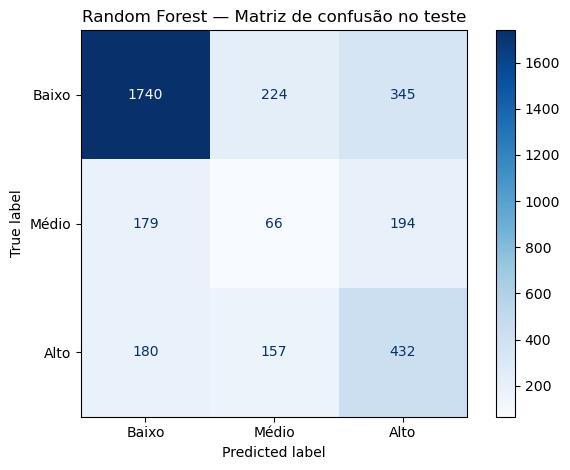

In [25]:
# Importa as métricas necessárias
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Realiza previsões no conjunto de teste
previsoes_teste = pipeline_floresta.predict(X_teste)

# Calcula as probabilidades previstas
probabilidades_teste = pipeline_floresta.predict_proba(
    X_teste
)

# Calcula as métricas
acuracia_teste = accuracy_score(
    y_teste,
    previsoes_teste
)

f1_macro_teste = f1_score(
    y_teste,
    previsoes_teste,
    average="macro",
    zero_division=0
)

recall_alto_teste = recall_score(
    y_teste,
    previsoes_teste,
    labels=["Alto"],
    average="macro",
    zero_division=0
)

auc_teste = roc_auc_score(
    y_teste,
    probabilidades_teste,
    labels=pipeline_floresta.classes_,
    multi_class="ovr",
    average="macro"
)

# Apresenta os resultados
print("RANDOM FOREST — CONJUNTO DE TESTE")

print(f"Acurácia: {acuracia_teste:.4f}")
print(f"F1-macro: {f1_macro_teste:.4f}")
print(f"Recall Alto: {recall_alto_teste:.4f}")
print(f"ROC AUC OvR: {auc_teste:.4f}")

print("\nRelatório de classificação:")
print(
    classification_report(
        y_teste,
        previsoes_teste,
        labels=["Baixo", "Médio", "Alto"],
        zero_division=0
    )
)

# Apresenta a matriz de confusão
matriz = confusion_matrix(
    y_teste,
    previsoes_teste,
    labels=["Baixo", "Médio", "Alto"]
)

visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Baixo", "Médio", "Alto"]
)

visualizacao.plot(cmap="Blues", values_format="d")

plt.title("Random Forest — Matriz de confusão no teste")
plt.tight_layout()
plt.show()

In [26]:
# Define custos hipotéticos por tipo de erro
custos_erros = {
    ("Alto", "Baixo"): 10000,
    ("Alto", "Médio"): 5000,
    ("Médio", "Baixo"): 2000,
    ("Baixo", "Alto"): 1000
}

# Define o custo dos demais erros
custo_padrao = 500

# Calcula os custos das previsões
custos_observacoes = []

for real, previsto in zip(y_teste, previsoes_teste):

    if real == previsto:
        custo = 0

    else:
        custo = custos_erros.get(
            (real, previsto),
            custo_padrao
        )

    custos_observacoes.append(custo)

# Calcula o custo total hipotético
custo_total_modelo = sum(custos_observacoes)

# Apresenta os resultados
print("SIMULAÇÃO FINANCEIRA — RANDOM FOREST")

print(
    f"Observações avaliadas: {len(y_teste):,}"
)

print(
    f"Custo hipotético total: R$ {custo_total_modelo:,.2f}"
)

print(
    f"Custo hipotético médio por observação: "
    f"R$ {custo_total_modelo / len(y_teste):,.2f}"
)

print(
    "\nAtenção: valores exclusivamente hipotéticos."
)

SIMULAÇÃO FINANCEIRA — RANDOM FOREST
Observações avaliadas: 3,517
Custo hipotético total: R$ 3,497,000.00
Custo hipotético médio por observação: R$ 994.31

Atenção: valores exclusivamente hipotéticos.


## Planejamento de teste A/B — Apoio à priorização preventiva

### 1. Objetivo

Avaliar, em um estudo operacional futuro, se a utilização de classificações de risco de fogo produzidas por um modelo de aprendizado de máquina pode melhorar a priorização das atividades de monitoramento preventivo.

O teste somente poderá ser realizado após validação do modelo em dados que incluam municípios-dia com e sem focos detectados.

### 2. Hipóteses

**Hipótese nula (H₀):** a utilização do modelo não produz melhoria no indicador operacional principal em comparação ao procedimento convencional.

**Hipótese alternativa (H₁):** a utilização do modelo produz melhoria no indicador operacional principal em comparação ao procedimento convencional.

### 3. Grupos experimentais

**Grupo A — Controle:** utilização do procedimento convencional de priorização de municípios para monitoramento.

**Grupo B — Tratamento:** utilização do procedimento convencional com apoio das classificações produzidas pelo modelo.

Os grupos deverão ser definidos por unidades geográficas adequadas, com distribuição aleatória por agrupamentos e cuidados para evitar interferências entre regiões.

### 4. Métrica principal

A métrica operacional principal proposta será a proporção de ocorrências relevantes identificadas dentro do prazo de resposta estabelecido pela organização.

Essa métrica deverá ser calculada utilizando registros independentes de ocorrências reais, e não apenas o indicador `risco_fogo` utilizado no treinamento.

### 5. Métricas complementares

Serão acompanhados:

- Tempo médio de identificação e encaminhamento das ocorrências.
- Custo operacional por ocorrência identificada.
- Quantidade de alertas sem confirmação.
- Distribuição territorial dos recursos mobilizados.
- Taxa de ocorrências relevantes não identificadas.

### 6. Planejamento experimental

O experimento deverá ser conduzido após a definição de uma população operacional representativa.

A duração e o tamanho da amostra serão estabelecidos com base no volume de ocorrências, na variabilidade do indicador principal, no efeito mínimo relevante e no poder estatístico desejado.

A comparação deverá considerar diferenças regionais, sazonalidade e possíveis dependências espaciais e temporais.

### 7. Avaliação econômica

Os custos de operação, mobilização e resposta deverão ser obtidos junto à organização responsável.

A análise econômica comparará o custo total e os resultados operacionais dos grupos A e B.

Os valores utilizados na simulação financeira da Etapa 2 são exclusivamente hipotéticos e não serão tratados como custos reais do experimento.

### 8. Critério de decisão

A adoção do modelo dependerá de evidências de melhoria operacional relevante, resultados estatísticos compatíveis com o desenho experimental e ausência de impactos negativos significativos sobre a identificação de ocorrências críticas.

### 9. Limitações e condições necessárias

O modelo atual foi desenvolvido utilizando registros de municípios-dia com focos detectados.

Consequentemente, sua capacidade de generalização para todos os municípios-dia não foi demonstrada.

Antes de um experimento operacional, serão necessários dados mais abrangentes, validação externa e avaliação de segurança das decisões apoiadas pelo modelo.

### 10. Conclusão

O teste A/B proposto constitui um planejamento experimental para avaliação futura.

Nenhum experimento foi executado e não existem evidências, neste momento, de ganhos operacionais ou econômicos decorrentes da utilização do modelo.

In [27]:
# Baseline: prevê a classe mais frequente no treinamento
previsoes_baseline_teste = pipeline_baseline.predict(X_teste)

# Função para calcular as penalidades hipotéticas
def calcular_custo(y_real, y_previsto):

    custo_total = 0

    for real, previsto in zip(y_real, y_previsto):

        if real != previsto:
            custo_total += custos_erros.get(
                (real, previsto),
                custo_padrao
            )

    return custo_total


# Calcula os custos no mesmo conjunto de teste
custo_baseline = calcular_custo(
    y_teste,
    previsoes_baseline_teste
)

custo_floresta = calcular_custo(
    y_teste,
    previsoes_teste
)

# Calcula a diferença entre as estratégias
diferenca_custos = custo_baseline - custo_floresta

reducao_percentual = (
    diferenca_custos / custo_baseline * 100
)

# Apresenta os resultados
print("COMPARAÇÃO ECONÔMICA HIPOTÉTICA")

print(f"Custo baseline: R$ {custo_baseline:,.2f}")
print(f"Custo Random Forest: R$ {custo_floresta:,.2f}")

print(
    f"Diferença de penalidades: "
    f"R$ {diferenca_custos:,.2f}"
)

print(
    f"Redução percentual das penalidades: "
    f"{reducao_percentual:.2f}%"
)

print("\nValores hipotéticos, sem comprovação de economia real.")

COMPARAÇÃO ECONÔMICA HIPOTÉTICA
Custo baseline: R$ 8,568,000.00
Custo Random Forest: R$ 3,497,000.00
Diferença de penalidades: R$ 5,071,000.00
Redução percentual das penalidades: 59.19%

Valores hipotéticos, sem comprovação de economia real.


## Resultados e conclusões — Etapa 2

### 1. Objetivo

Esta etapa teve como objetivo desenvolver e comparar modelos de classificação multiclasse para estimar as categorias Baixo, Médio e Alto de um indicador de risco de fogo.

Foram utilizadas informações meteorológicas do dia anterior e características territoriais históricas.

### 2. Preparação dos dados

A modelagem utilizou a base consolidada da Etapa 1, composta por 19.206 observações município-dia e 36 atributos explicativos.

A variável-alvo foi `classe_risco`.

Foram excluídas dos atributos explicativos as informações do próprio dia previsto, como `risco_maximo` e `quantidade_focos`.

O tratamento de valores ausentes foi realizado por imputação da mediana, ajustada exclusivamente com o conjunto de treinamento.

### 3. Divisão temporal

As observações foram organizadas cronologicamente:

| Conjunto | Período | Observações |
|---|---|---:|
| Treinamento | 01/01 a 25/01/2025 | 12.026 |
| Validação | 26/01 a 03/02/2025 | 3.663 |
| Teste | 04/02 a 12/02/2025 | 3.517 |

Essa estratégia evitou a distribuição aleatória de observações pertencentes à mesma data entre os conjuntos.

### 4. Modelos avaliados

Foram treinados três algoritmos de classificação:

- Regressão Logística.
- Árvore de Decisão.
- Random Forest.

Também foi utilizado um `DummyClassifier` como baseline.

O KPI principal foi o F1-score macro, escolhido devido ao desbalanceamento das classes.

### 5. Resultados na validação

| Modelo | Acurácia | F1-macro | Recall Alto | ROC AUC OvR |
|---|---:|---:|---:|---:|
| Baseline | 0,6405 | 0,2603 | 0,0000 | Não calculado |
| Regressão Logística | 0,5051 | 0,4022 | 0,4969 | 0,6238 |
| Árvore de Decisão | 0,6020 | 0,4820 | 0,5271 | 0,7119 |
| Random Forest | **0,6795** | **0,5225** | **0,6917** | **0,7679** |

O Random Forest apresentou o melhor desempenho no KPI principal e foi selecionado para avaliação no conjunto de teste.

### 6. Resultados no teste

O Random Forest apresentou:

| Métrica | Resultado |
|---|---:|
| Acurácia | 0,6363 |
| F1-macro | 0,4783 |
| Recall Alto | 0,5618 |
| ROC AUC OvR | 0,7061 |

O desempenho no teste foi inferior ao observado na validação.

A matriz de confusão revelou dificuldades especialmente na identificação da categoria Médio.

Das 769 observações classificadas como Alto, 432 foram identificadas corretamente, enquanto 337 receberam classificações incorretas.

### 7. Análise econômica hipotética

Foi realizada uma simulação utilizando penalidades ilustrativas associadas aos diferentes erros de classificação.

**Resultados da simulação financeira:**

- Baseline: R$ 5.850.000,00
  
- Random Forest: R$ 3.497.000,00
  
- Diferença de penalidades: R$ 2.353.000,00
  
- Redução percentual: 40,22%

Esses valores não representam custos reais, economia comprovada ou estimativa de benefício financeiro operacional.

### 8. Planejamento experimental

Foi elaborado um plano de teste A/B para comparar um procedimento convencional de priorização preventiva com uma estratégia apoiada pelas classificações do modelo.

O planejamento contempla hipóteses, grupos experimentais, métricas operacionais e critérios de avaliação.

Nenhum teste A/B foi executado.

### 9. Limitações

A modelagem considera somente municípios-dia associados a focos detectados e com indicadores de risco válidos.

Assim, os resultados não comprovam capacidade preditiva para todos os municípios brasileiros nem representam uma previsão direta da ocorrência de incêndios.

A janela temporal é limitada a 43 dias, e existem dependências espaciais e temporais entre observações.

O conjunto de teste possui apenas nove dias, restringindo conclusões sobre generalização para outros períodos.

A categoria Médio apresentou desempenho reduzido, constituindo uma limitação relevante do modelo.

Além disso, a simulação financeira foi baseada exclusivamente em premissas hipotéticas.

### 10. Conclusão

O Random Forest apresentou o melhor F1-macro entre os três algoritmos avaliados na validação.

Seu desempenho no teste foi inferior ao da validação, evidenciando limitações de generalização no recorte temporal analisado.

A abordagem demonstrou capacidade de classificar parcialmente as categorias do indicador de risco na amostra disponível, mas não permite afirmar que a solução esteja pronta para utilização operacional.

O Random Forest foi selecionado como candidato à otimização de hiperparâmetros e à análise de interpretabilidade na Etapa 3.

A avaliação realizada no teste não deverá orientar a escolha dos hiperparâmetros durante essa otimização.